### Innovation.
This new version improves upon the last iteration in the following domain:
- sensors precision and ODR from datasheets
- regular sensor sampling rate
- linear kalman filtering on height and its two derivatives

Further iterations shall incorporate a non-linear filter that includes a linearization for $v^2$, $C_d$ as well as $u$ and **B** for modelling the control outputs of the airbrakes. 

In [2]:
import queue
import numpy as np
from typing import Callable, Optional


class HiddenSystemState: 
    timestamp: float = None
    acceleration:float = None
    velocity:float  = None
    height: float = None

    temperature: float = None
    air_density: float = None
    air_pressure: float = None

    def __init__(self,ts,a,v,h,t,ad,ap):
        self.timestamp = ts
        self.acceleration = a
        self.velocity = v
        self.height = h
        self.temperature = t
        self.air_density = ad
        self.air_pressure = ap


    
class Sensor:
    std_dev: float = None
    name: str = ""
    output_data_rate: int = 1 # in Hz
    output_data: queue.Queue = queue.Queue()

    systemState: HiddenSystemState = None
    lastTickTs: float = 0    

    def __init__(self,name_, std_dev_, odr_, systemStateRef_, getTargetVar_: Callable[[HiddenSystemState],float]):
        self.name = name_
        self.std_dev = std_dev_
        self.output_data_rate = odr_
        self.systemState = systemStateRef_
        self.getTargetValue = getTargetVar_

    def _generateSample(self) -> float:
        physicalValue:float = self.getTargetValue(self.systemState)
        z = np.random.normal(physicalValue,self.std_dev,1)
        return z

    def reset(self):
        self.lastTickTs = 0
        self.output_data.clear()

    def tick(self, ts:float):
        """
        Checks the time that has passed since last tick and populates the output_data queue
        according to the ODR.
        """
        if ts - self.lastTickTs > (1.0 / self.output_data_rate):
            self.lastTickTs = ts
            sample = self._generateSample()
            self.output_data.put(sample)

class AirBrake:
    max_linear_velocity:float = 0.05125*4
    
    ext:float = 0.0

    target_extension: float = 0.0

    #sim_timestep: float = None

    def __init__(self):
        #self.sim_timestep = dt
        pass

    def move(self, dt):
        if dt <= 0:
            return
        if self.target_extension != self.ext:
            # If doable in this timestep, do so
            if abs(self.target_extension - self.ext) < (dt*self.max_linear_velocity)/constants.AIRBRAKE_FLAP_WIDTH:
                self.ext = self.target_extension
            else:
                # take the max step in the right direction
                max_percentage_step = (dt*self.max_linear_velocity)/constants.AIRBRAKE_FLAP_WIDTH

                if self.target_extension < self.ext:
                    self.ext -= max_percentage_step
                else:
                    self.ext += max_percentage_step
    
    def setTarget(self,target:float):
        assert 0.0 <= target <= 1.0, "Target must be valid position from 0 to 1"
        if target != self.target_extension:
            self.target_extension = target

    def getExtension(self) -> float:
        return self.ext



The IMU's have different operation modes, from 4 to 32 or 24g. The maximum deceleration we will experience after motor burnout is (without airbrakes) about -1.21G which means we are safe to use the finest resolution of 4G and will continue under this assumption. 

Important: Testing is required to check, whether the barometers precision holds under the rockets conditions, as it is in a closed tube and experiences acceleration.

In [3]:
# # Setup States and Sensors
# sysState = HiddenSystemState(ts=3.0, a=-9.81,v=129.0,h=250.0,t=25.0,ad=1.225,ap=101_325)

# primary_imu = Sensor("LSM6DSO32",0.03139,1600,sysState,lambda s: s.acceleration)
# secondary_imu = Sensor("BMI088",0.0262644,1600,sysState, lambda s: s.acceleration)
# barometer = Sensor("DPS368",0.35,26,sysState,lambda s: s.air_pressure)

In [4]:
# The data our algorithm predicts and collects (AirBrakeSoftwareData)
class ABSData:
    rawHeight: float
    kalmanHeight: float

    kalmanVelocity: float

    rawAcceleration: float
    kalmanAcceleration: float

    cdEstimate: float
    apogeeEstimate: float

    def __init__(self,rawH,kalH,kalV,rawA,kalA,cdEst,apogeeEst):
        self.rawHeight = rawH
        self.kalmanHeight = kalH
        self.kalmanVelocity = kalV
        self.rawAcceleration = rawA
        self.kalmanAcceleration = kalA
        self.cdEstimate = cdEst
        self.apogeeEstimate = apogeeEst
    

# The actual simulated data
class FlightLogEntry:
    timestamp: int
    height: float
    verticalVelocity: float
    verticalAcceleration: float

    airbrakeExtension: float

    controlSoftwareData: Optional[ABSData]
    absExecutionTime: float

    def __init__(self,ts,height,verticalVel,verticalAcc, airbrakeExt, absStruct,absExecutionTime):
        self.timestamp = ts
        self.height = height
        self.verticalVelocity = verticalVel
        self.verticalAcceleration = verticalAcc
        self.airbrakeExtension = airbrakeExt
        self.controlSoftwareData = absStruct
        self.absExecutionTime = absExecutionTime

In [32]:
import math
import time
import numpy as np
from typing import Callable, TypeAlias, Sequence
from scipy import integrate as itg

import helpers
import constants


# max deviation currently around 5%, this could mess up the kalman filter
CODE_RUN_FREQUENCY = 120
TIMESTEP = 1 / CODE_RUN_FREQUENCY


flightLogs: list[FlightLogEntry] = []

"""
    @brief The function that will be called from the simulation looop each iteration.
    @param timestamp [float]
    @param primary_imu [Sensor]
    @param secondary_imu [Sensor]
    @param baro [Sensor]
    @param targetApogee [float]
    @return Extension state of the airbrake [float] as well as the [ABSData] for logging.
"""
AirbrakeControlSoftwareCallback: TypeAlias = Callable[[float, Sensor, Sensor, Sensor, float], tuple[float, ABSData]]


def updateSystemState(state: HiddenSystemState,t:float, h:float, v:float, a:float):
    state.height = h
    state.timestamp = t
    state.velocity = v
    state.acceleration = a
    state.temperature = helpers.tempFromHeight(h)

    state.air_density = helpers.airDensityFromHeight(h)
    state.air_pressure = helpers.airPressureFromHeight(h)


"""
    @brief Runs the simulation.
    @param targetApogee [float]
    @param t0 Simulation start time [float]
    @param h0 initialHeight [float]
    @param t0 initialVelocity [float]
    @param controlSoftware [AirbrakeControlSoftwareCallback]
    @return List of the LogEntries [list<FlightLogEntry>]
"""
def runSimulation(targetApogee,t0, h0, v0, controlSoftware:AirbrakeControlSoftwareCallback) -> Sequence[FlightLogEntry]:
    global SENSOR_SETTING_HEIGHT_READ_NOISEFACTOR,SENSOR_SETTING_VEL_READ_NOISEFACTOR
    flightLogs = []

    systemState  = HiddenSystemState(ts=0, a=0,v=0,h=0,t=0,ad=0,ap=0)


    # primary_imu = Sensor("LSM6DSO32",0.03139,1600,systemState,lambda s: s.acceleration)
    primary_imu = Sensor("LSM6DSO32",0.1,1600,systemState,lambda s: s.acceleration)
    secondary_imu = Sensor("BMI088",0.0262644,1600,systemState, lambda s: s.acceleration)
    barometer = Sensor("DPS368",0.35,26,systemState,lambda s: s.height)

    ## Setup the airbrake
    airbrake = AirBrake()

    all_sensors = [primary_imu,secondary_imu,barometer]
    """
         Execution order
        <===============>

        1) calculate state & forces
        1.b) let the sensors tick
        2) save state
        3) do logging
        4) execute control software and capture Airbrake ext. for next iteration
        5) return itg variables

    """

    last_control_software_execution = 0
    last_dyn_sys_timestep = t0 # used for physical movement of servo Airbrake
    def dynamicSystem(t,x_data):
        # nonlocal primary_imu, secondary_imu, barometer
        nonlocal flightLogs, airbrake, last_control_software_execution, all_sensors, last_dyn_sys_timestep
        x = x_data[0]
        v = x_data[1]

        airbrake_extension_level = airbrake.getExtension()

        dx_dt = v    # x' = v
        currentAltitudeAirDensity = helpers.airDensityFromHeight(x)

        # We can make this a function of height/velocity to simulate oscillations (maybe between 85° and 95°)
        crossSectionalArea = (math.pi * (constants.ROCKET_OUTER_DIAMETER_M/2)**2) # m²

        # F_D = 1/2 p A C_d v²
        bodyDragForce = (1/2) * currentAltitudeAirDensity * crossSectionalArea * constants.ROCKET_DEFAULT_CD * (v**2)
        airbrakeDragForce = helpers.airbrakeAdditionalDragForce(airbrake_extension_level,constants.ROCKET_AIRBRAKE_DEFAULT_CD,v,currentAltitudeAirDensity)
        dy_dt = -9.81 - (bodyDragForce + airbrakeDragForce)/constants.ROCKET_BURNOUT_MASS

        ## Tell sensors to push into their queue
        for s in all_sensors:
            s.tick(t)
        
        ## Update the system state
        airbrake.move(t-last_dyn_sys_timestep)
        updateSystemState(systemState,t,x,v,dy_dt)

        absUnitLog = None
        absExecutionTime = None
        # Check if it is time for another control software execution to achieve wanted frequency
        if t - last_control_software_execution > TIMESTEP:
            last_control_software_execution = t
            timeBeforeExec = time.perf_counter()
            (target_ab_extension, absUnitLog) = controlSoftware(t,primary_imu,secondary_imu,barometer,airbrake, targetApogee)

            # Tell the servo to move
            airbrake.setTarget(target_ab_extension)
            
            absExecutionTime = time.perf_counter() - timeBeforeExec

            
        logEntry = FlightLogEntry(t,x,v,dy_dt, airbrake_extension_level,absUnitLog,absExecutionTime)
        flightLogs.append(logEntry)

        last_dyn_sys_timestep = t
        return [dx_dt, dy_dt]

    # The max_step is a problem right now. Our check would allow .9 TS without a CS retrigger
    # and then if it did 1 TS we would have 1.9 TS instead of 1TS. As a hotfix I decreased granularity to TS/10
    # so that the filters aren't thrown off because of too much inconsistency.
    solver = itg.RK45(dynamicSystem, t0, [h0, v0], 500, max_step=TIMESTEP/10) 
    stepCount = 0
    while solver.status == "running":
        solver.step()
        stepCount += 1

        # Checking of y = 0 is hit to terminate simulation
        if solver.y[0] <= 0:
            break

    print(f"Solver status: {solver.status}. Steps: {stepCount}")
    return flightLogs



## ABS Software
#### State Filtering
We use a Kalman filter to filter the z-acceleration, z-velocity and height of the rocket. Our state vector is 
$$
x = \begin{bmatrix} x \\  \dot x \\ \ddot x \\ \dddot x\end{bmatrix}
$$ 


I'll start off with a simplified measurement vector that only includes one of the two IMU readings.
$$ 
z = \begin{bmatrix} acc_{1} \\ \text{height} \end{bmatrix}
$$

The state transitiion matrix we get 

$$
F = \begin{bmatrix}1& dt& dt²/2\\0& 1& dt\\0& 0& 1 \end{bmatrix}
$$

(Actually dim = 4 now, update!)

where *dt* is our TIMESTEP and constant.

To estimate the process noise, we will start out with filterpy's discrete white noise according to a wiener process.


## C_d estimation
Since the velocity is crucial for the calculation of the $C_d$ of the airbrakes, we will wait for the filtered value to settle, so start at $t_0 = 3.6s$. In the real version this won't be necessary, as the filter is also running throughout the motor-burning phase and will be quite on point even at $3s$.

An inherent problem is that I use the same model for airbrake extension and its impact in the simulation and the control software, so they will by defintion agree. To mitigate this, I could cheaply simulate unknown turbulences, by mapping airbrake extension not to a linear function, but one that jumps up a bit when the extension is slightly above 0 (due to turbulences caused) and then increases further up to its max in a linear fashion, a bit like the following function.
$c(x)=1-e^{-15x}+0.05x$

### KF Setup
We are working with the following function to calculate $C_dA =: k$:

$$
k(a,v) = \frac{2m(g-a)}{pv^2}
$$
Where $m$ is the dry mass, $g$ approx. $-9.8m/s^2$ and $p$ the air density at around $1.225 kg/m^3$. 


#### State 
$$
k = C_d * A
$$
$$
x = \begin{bmatrix} k \\  \dot k\end{bmatrix}
$$

#### Transfer Function
This is a second order Kalman filter, so the transfer function is quite simple:
$$
F = \begin{bmatrix} 1 & dt \\ 0 & 1\end{bmatrix}
$$


#### Measurement Noise

We need to estimate the [propagation of uncertainty](https://en.wikipedia.org/wiki/Propagation_of_uncertainty) that we transfer from our state (pos/vel/acc/jerk) kalman filter. I should use the current variance provided in the filter which will hopefully converge to the sensors variances.

First we linearize $k(a,v)$ around our current a & v estimates using a first order Taylor expansion. The $f_0$ term can be used as the state estimate for $C_dA$ while the Jacobian tells us how to transform the covariance matrix of a and v into the uncertainty for $C_dA$.

$$
J = \begin{bmatrix} \frac{\partial{k}}{\partial{v}} \\ \frac{\partial{k}}{\partial{a}}\end{bmatrix} = \begin{bmatrix} \frac{-6m(g-a)}{pv^3} \\ \frac{-2m}{pv^2} \end{bmatrix}
$$

We can then extract $v$ and $a$ uncertainties from our $P$ matrix from the state kalman filter and transform them like so into a new covariance matrix for the C_dA:
$$
P_{CdA} = JPJ^T
$$

As to make sure the values and variances have settled, the initalization of this filter will start about .5 seconds after burnout.

#### Process Noise
The max variance we expect between time steps is $A_{total} * \text{maxServoVelocity} * dt$, so we will go with that and a discrete Wiener process.




In [33]:
def setupStateKalmanFilter(z_acc1,imu1, z_height, baro) -> KalmanFilter:
    kf = kalman.KalmanFilter(dim_x=4,dim_z=2)


    # Process Noise: For process noise, assume discrete time Wiener process 
    kf.Q = Q_discrete_white_noise(dim=4,dt=TIMESTEP,var=MAX_SNAP**2)

    # State Transition Matrix
    kf.F = np.array([[1,TIMESTEP, TIMESTEP**2/2, TIMESTEP**3/6],
                                [0,1,TIMESTEP,TIMESTEP**2 / 2],
                                [0,0,1, TIMESTEP],
                                [0,0,0,1]])

    # Measurement Function: only using one of the IMU's for now
    kf.H = np.array([[0,0,1,0],
                            [1,0,0,0]])

    # Measurement Noise Matrix: starting with no cov
    kf.R = np.array([[imu1.std_dev**2,0],
                            [0,baro.std_dev**2]])

    # Inital conditions: Use first measurement or default value
    i_x,i_xv = (z_height[0],baro.std_dev**2) if z_height else (200,100)
    i_v,i_vv = (120,20)
    i_a,i_av = (z_acc1[0],(imu1.std_dev)**2) if z_acc1 else (-10,50)
    i_j,i_jv = (0.5,10)
    kf.x = np.array([i_x,i_v,i_a,i_j])
    
    # Inital Variance: If measurement use sensors variance, else big one to show uncertainty
    kf.P = np.array([[i_xv,0,0,0],
                    [0,i_vv,0,0],
                    [0,0,i_av,0],
                    [0,0,0,i_jv]])
    return kf

In [51]:
"""
def CdA(v,a) -> float:
    m = constants.ROCKET_BURNOUT_MASS
    p = 1.225 # make this dependent on height
    g = -9.81
    return (2*m*(g-a))/ (p * v**2)

def cdaFilterMeasurementNoise(stateKF: KalmanFilter) -> np.array:
    m = constants.ROCKET_BURNOUT_MASS
    p = 1.225 # make this dependent on height
    g = -9.81

    v0 = stateKF.x[1]
    a0 = stateKF.x[2]
    velAccP = stateKF.P[1:3, 1:3]
    
    dk_dv = (-6*m*(g-a0))/(p*v0**2)
    dk_da = (-2*m)/(p*v0**2)
    J = np.array([dk_dv,dk_da])

    return J @ velAccP @ J.T

def setupCDAFilter(stateKF: KalmanFilter, airBrake: AirBrake) -> KalmanFilter:
    

    B_scale = 0.0
    m = constants.ROCKET_BURNOUT_MASS
    p = 1.225 # make this dependent on height
    g = -9.81

    kf = kalman.KalmanFilter(dim_x=2, dim_z=1,dim_u=1)

    ## Process noise (Q) with max variance of biggest derivative
    A_total = 3 * constants.AIRBRAKE_FLAP_HEIGHT * constants.AIRBRAKE_FLAP_WIDTH 
    servo_max_velocity = airBrake.max_linear_velocity
    max_delta = A_total*servo_max_velocity * TIMESTEP

    kf.Q = Q_discrete_white_noise(dim=2,dt=TIMESTEP,var=max_delta**2)

    ## State Transition Model (without B & u!)
    kf.F = np.array([[1,TIMESTEP],
                     [0,1]])

    ## Inital State: f_0 calculated with the means (so state of stateKf) and CdA(v,a)
    v0 = stateKF.x[1]
    a0 = stateKF.x[2]

    kf.x = np.array([
        CdA(v=v0, a=a0),
        0
    ])

    ## Inital Variance estimate (P)
    kf.P = np.array([[(CdA(v0,a0))**2, 0],
                     [0,10]])
    # we use the fact, that cda is known to be > 0 so that is our 3 sigma region.

    ## State to Measurement (H)
    kf.H = np.array([[1.0, 0.0]])

    ## Measurement Noise (R): Propagated variance from acceleration and velocity of stateKF
    ## ! This should be updated from time to time, as it depends on linearization!
    # velAccP = stateKF.P[1:3, 1:3]
    
    # dk_dv = (-6*m*(g-a0))/(p*v0**2)
    # dk_da = (-2*m)/(p*v0**2)
    # J = np.array([dk_dv,dk_da])

    # kf.R = J @ velAccP @ J.T
    kf.R = cdaFilterMeasurementNoise(stateKF)

    ## Setup the control matrix

    kf.B = np.array([[B_scale * A_total * constants.ROCKET_AIRBRAKE_DEFAULT_CD / TIMESTEP], [0.0]])

    return kf
    """;

In [ ]:
## Trying a first order filter for the CdA, with control inputs and process noise covering motion 

def CdA(v,a) -> float:
    m = constants.ROCKET_BURNOUT_MASS
    p = 1.225 # make this dependent on height
    g = -9.81
    return (2*m*(g-a))/ (p * v**2)

def cdaFilterMeasurementNoise(stateKF: KalmanFilter) -> np.array:
    m = constants.ROCKET_BURNOUT_MASS
    p = 1.225 # make this dependent on height
    g = -9.81

    v0 = stateKF.x[1]
    a0 = stateKF.x[2]
    velAccP = stateKF.P[1:3, 1:3]
    
    dk_dv = (-6*m*(g-a0))/(p*v0**2)
    dk_da = (-2*m)/(p*v0**2)
    J = np.array([dk_dv,dk_da])

    return J @ velAccP @ J.T

def setupCDAFilter(stateKF: KalmanFilter, airBrake: AirBrake) -> KalmanFilter:

    m = constants.ROCKET_BURNOUT_MASS
    p = 1.225 # make this dependent on height
    g = -9.81

    kf = kalman.KalmanFilter(dim_x=1, dim_z=1,dim_u=1)

    ## Process noise (Q) with max variance of biggest derivative
    A_total = 3 * constants.AIRBRAKE_FLAP_HEIGHT * constants.AIRBRAKE_FLAP_WIDTH 
    servo_max_velocity = airBrake.max_linear_velocity
    max_delta = A_total*servo_max_velocity * TIMESTEP

    ## The tracking variable is something we are really sure about
    kf.Q = np.array([[max_delta**2]]) 
    # Q_discrete_white_noise(dim=1,dt=TIMESTEP,var=max_delta**2)

    ## State Transition Model
    kf.F = np.array([[1]])

    ## Inital State: f_0 calculated with the means (so state of stateKf) and CdA(v,a)
    v0 = stateKF.x[1]
    a0 = stateKF.x[2]

    kf.x = np.array([CdA(v=v0, a=a0)])

    ## Inital Variance estimate (P)
    kf.P = np.array([[(CdA(v0,a0))**2]])
    # we use the fact, that cda is known to be > 0 so that is our 3 sigma region.

    ## State to Measurement (H)
    kf.H = np.array([[1.]])

    ## Measurement Noise (R): Propagated variance from acceleration and velocity of stateKF
    kf.R = cdaFilterMeasurementNoise(stateKF)
    print("R: ", kf.R)

    ## Setup the control matrix
    print("A-total: ", A_total)
    kf.B = np.array([A_total * constants.ROCKET_AIRBRAKE_DEFAULT_CD])

    return kf

In [256]:
from filterpy import kalman
from filterpy.common import Q_discrete_white_noise, Saver

# Data on our sensors.

def approachU(old_u,target_u,alpha=0.97)->float:
    return alpha*old_u + (1.0-alpha) * target_u

def ascent(v0, g, CdA, m):
     
    bodyCdA = constants.ROCKET_DEFAULT_CD*((constants.ROCKET_OUTER_DIAMETER_M/2)**2 * math.pi)
    # print(f"CdA:{CdA} / body CdA:{bodyCdA} ")
    combined_cda = CdA #+ bodyCdA
    k = combined_cda / (2*m)
    w = np.sqrt(g*k)
    th0 = np.arctan(v0*np.sqrt(k/g))
    t_apo = th0 / w
    h_apo = np.log1p(k*v0**2/g) / (2*k)
    # h = lambda t: np.log(np.cos(th0 - w*t) / np.cos(th0)) / k
    # v = lambda t: np.sqrt(g/k) * np.tan(th0 - w*t)
    return t_apo, h_apo #, h, v

def initalExtension():
    ## Could do numerical solving, but I'll just do a smart brute force
    for u in np.linspace(0,1,50):
        cda = u * 2

CDA_ESTIMATE_START_T = 3.7

MAX_SNAP = 0.428 # derived with numerical differentation of simulated acceleration.

stateFilter_ = None
cdaFilter_ = None

stateSave = None
cdaSaver_ = None
last_u = None
first_run = True
def airbrakeControlSoftware(t:float, imu1: Sensor, imu2: Sensor, baro: Sensor, airBrake:AirBrake, targetApogee: float) -> tuple[float,Optional[ABSData]]:
    global stateFilter_, stateSave, cdaFilter_, cdaSaver_, last_u, first_run

    target_airbrake_extension = 0.0

    if last_u == None:
        last_u = airBrake.getExtension()
    
    # Get sensor measurements
    z_acc1 = imu1._generateSample()
    z_height = baro._generateSample()

    if stateFilter_ == None:
        # Setup the Kalman Filter
        stateFilter_ = setupStateKalmanFilter(z_acc1,imu1, z_height, baro)
        stateSave = Saver(stateFilter_)

    apogee_estimation = None
    # CDA phase has started
    if t >= CDA_ESTIMATE_START_T:
        if cdaFilter_ == None:
            cdaFilter_ = setupCDAFilter(stateFilter_, airBrake)
            cdaSaver_ = Saver(cdaFilter_)

            cdaFilter_.test_matrix_dimensions()
        
        act_ext = airBrake.getExtension()


        cda_guess = CdA(v=stateFilter_.x[1], a=stateFilter_.x[2])
        if act_ext != last_u:
            delta_u = act_ext - last_u
            cdaFilter_.u = np.array([delta_u])
            cdaFilter_.predict(delta_u)#u=np.array([act_ext]))
            last_u = act_ext
        else:
            cdaFilter_.predict()
            cdaFilter_.u = np.array([last_u])
        cdaFilter_.update(np.array([cda_guess]))
        cdaSaver_.save()


        ## If this is the first run, deploy the airbrakes to an estimated
        ## region that gets us somewhat close to target
        if first_run:
            
            target_airbrake_extension = 0.0

            first_run = False

        ## For now just update the linearization of R every iteration,
        ## can be done more sparingly on embedded though
       
        cdaFilter_.R = cdaFilterMeasurementNoise(stateFilter_)


        ## Estimating the apogee we will reach with current settings
        newest_cda = cdaFilter_.x[0]
        v0 = stateFilter_.x[1]
        h0 = stateFilter_.x[0]
        _, delta_height = ascent(v0, 9.81,newest_cda,constants.ROCKET_BURNOUT_MASS)

        apogee_estimation = h0 + delta_height


    # Predict and update
    stateFilter_.predict()
    stateFilter_.update(np.array([z_acc1, z_height]))
    stateSave.save()

    estState = stateFilter_.x
    logUnit = ABSData(rawH=z_height, rawA=z_acc1, kalH=estState[0], kalV=estState[1], kalA=estState[2], apogeeEst=apogee_estimation, cdEst=cdaFilter_.x[0] if cdaFilter_ else None)

    
    if t > 6:
        target_airbrake_extension = 0.8
    
    return (target_airbrake_extension,logUnit)


flightData:Sequence[FlightLogEntry] = runSimulation(960,constants.SIM_T0,constants.SIM_T0_HEIGHT,constants.SIM_T0_VELOCITY,airbrakeControlSoftware)

R:  5.24607084292241e-06
A-total:  0.0037637999999999994
CdA:0.003966405897359159 / body CdA:0.004105935934535716 
CdA:0.003946744427466928 / body CdA:0.004105935934535716 
CdA:0.003918136555104905 / body CdA:0.004105935934535716 
CdA:0.003918835960775664 / body CdA:0.004105935934535716 
CdA:0.003918314862204787 / body CdA:0.004105935934535716 
CdA:0.003925670824613517 / body CdA:0.004105935934535716 
CdA:0.0039156616153921435 / body CdA:0.004105935934535716 
CdA:0.0039105041961604485 / body CdA:0.004105935934535716 
CdA:0.003901088658606888 / body CdA:0.004105935934535716 
CdA:0.003898869159071718 / body CdA:0.004105935934535716 
CdA:0.0038954164551714488 / body CdA:0.004105935934535716 
CdA:0.003890554431513921 / body CdA:0.004105935934535716 
CdA:0.003887079497506337 / body CdA:0.004105935934535716 
CdA:0.0038828182740864438 / body CdA:0.004105935934535716 
CdA:0.0038740013492237577 / body CdA:0.004105935934535716 
CdA:0.003863783434192498 / body CdA:0.004105935934535716 
CdA:0.0038

Max jerk: 1.7004461285704053
Max snap: 1557.6671795172304


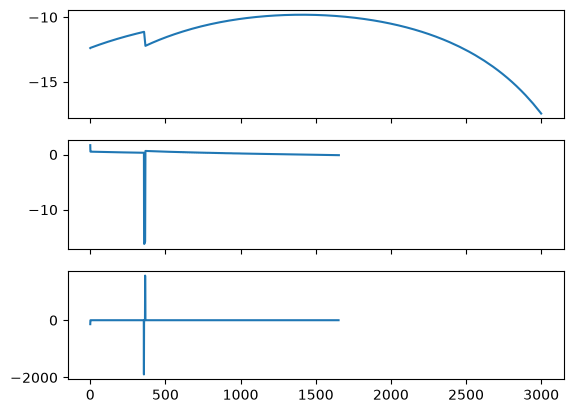

In [257]:
from matplotlib import pyplot as plt

## Analyse the filter performance

## To get a good estimate on the process noise variance assuming a wiener process,
## we must know the max snap, or change in jerk.
accs = np.array([i.verticalAcceleration for i in flightData if i.controlSoftwareData is not None])

dt = TIMESTEP
## Numerically diff once for jerk
jerks = []
for i in range(len(actualAccelerations)-2):
    jerks.append((accs[i+1] - accs[i]) / dt)

print(f"Max jerk: {max(jerks)}")


## Numerically diff once for jerk
snaps = []
for i in range(len(jerks)-2):
    snaps.append((jerks[i+1] - jerks[i]) / dt)

print(f"Max snap: {max(snaps)}")

# Plot the two below in two subplots with shared x axis
fig, (ax1, ax2,ax3) = plt.subplots(3, 1, sharex=True)

ax1.plot(accs)
ax2.plot(jerks)
ax3.plot(snaps);


## Data Analysis

Apogee: 985.1287538790755
Lin. Jerk:  0.6208594655716837


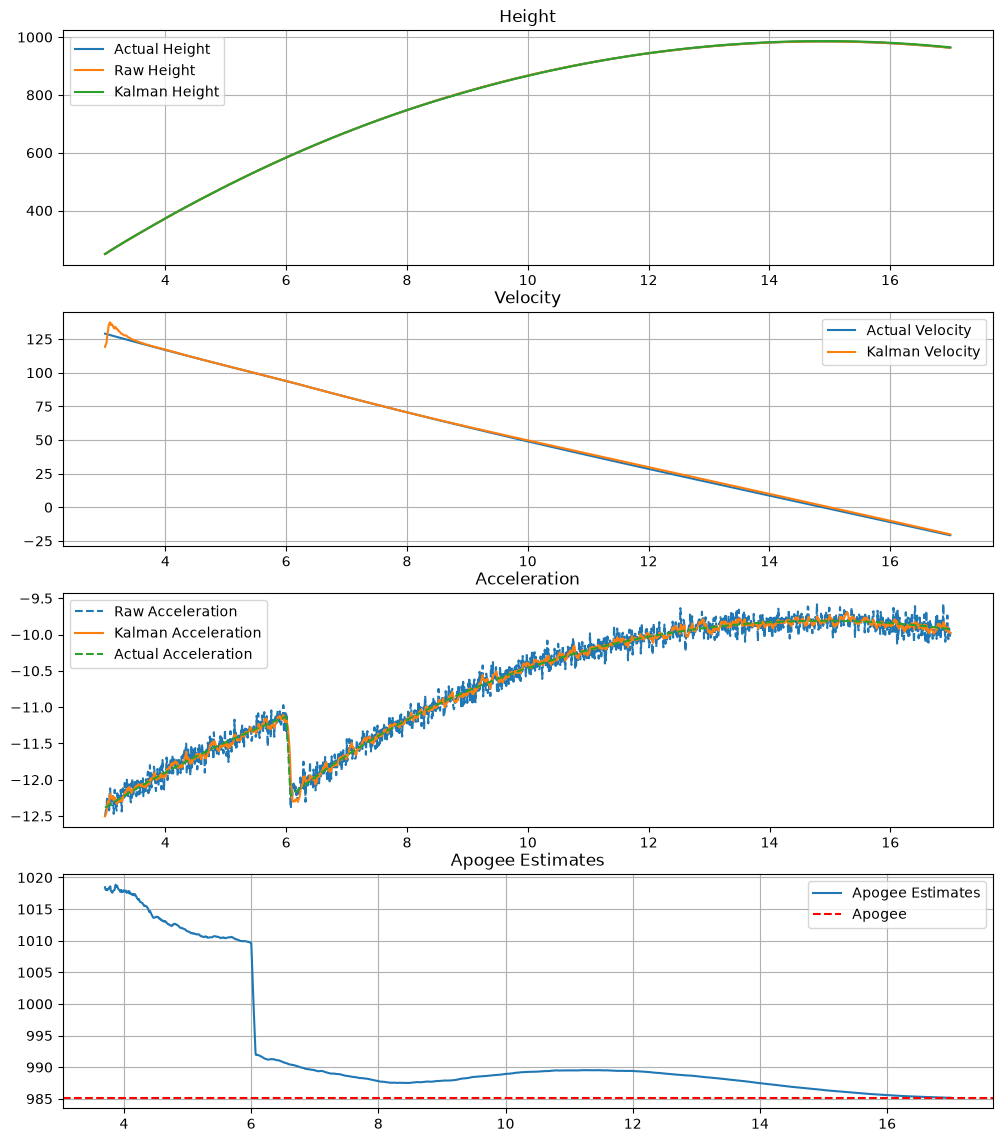

In [258]:
from matplotlib import pyplot as plt

dataStartTime = 0
dataEndTime = 17

# Analysing the data
t = np.array([i.timestamp for i in flightData if dataStartTime <= i.timestamp <= dataEndTime])
h = np.array([i.height for i in flightData if dataStartTime <= i.timestamp <= dataEndTime])

apogee = max(h)
apogee_time = [i.timestamp for i in flightData if i.height == apogee][0]


# filter out the AbsData timestamps, raw height and kalman height for plotting
absTimestamps = np.array([i.timestamp for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])
rawHeights = np.array([i.controlSoftwareData.rawHeight for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])
kalmanHeights = np.array([i.controlSoftwareData.kalmanHeight for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])

actualVelocity = np.array([i.verticalVelocity for i in flightData if dataStartTime <= i.timestamp <= dataEndTime])
kalmanVelocity = np.array([i.controlSoftwareData.kalmanVelocity for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])
 

# for accelerations
rawAccelerations = np.array([i.controlSoftwareData.rawAcceleration for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])
kalmanAccelerations = np.array([i.controlSoftwareData.kalmanAcceleration for i in
    flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])
actualAccelerations = np.array([i.verticalAcceleration for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])

# get the apogee estimations
apogeeEstimations = np.array([i.controlSoftwareData.apogeeEstimate for i in flightData if i.controlSoftwareData is not None and dataStartTime <= i.timestamp <= dataEndTime])

print(f"Apogee: {max(h)}")


fig, axs = plt.subplots(4,1,figsize=(12,14))
axs[0].plot(t,h,label="Actual Height")
axs[0].plot(absTimestamps,rawHeights,label="Raw Height")
axs[0].plot(absTimestamps,kalmanHeights,label="Kalman Height")
axs[0].set_title("Height")
axs[0].legend()
axs[0].grid(True)

axs[1].plot(t,actualVelocity,label="Actual Velocity")
axs[1].plot(absTimestamps,kalmanVelocity,label="Kalman Velocity")
axs[1].set_title("Velocity")
axs[1].legend()
axs[1].grid(True)

axs[2].plot(absTimestamps,rawAccelerations,label="Raw Acceleration",linestyle="dashed")
axs[2].plot(absTimestamps,kalmanAccelerations,label="Kalman Acceleration")
axs[2].plot(absTimestamps,actualAccelerations,label="Actual Acceleration",linestyle="dashed")
axs[2].set_title("Acceleration")
axs[2].legend()

# plot apogee estimates over time
axs[3].plot(absTimestamps,apogeeEstimations,label="Apogee Estimates")
axs[3].axhline(y=apogee,color="r",linestyle="--",label="Apogee")

axs[3].set_title("Apogee Estimates")
axs[3].legend()
axs[3].grid(True)

# Linearising the change in acceleration
dt = 0.1
a0 = actualAccelerations[0]
a1 = actualAccelerations[int(dt/TIMESTEP)]
delta_a = (a1-a0) / dt
print("Lin. Jerk: ", delta_a)


plt.grid(True)
plt.show()


Start tmime:  3.0


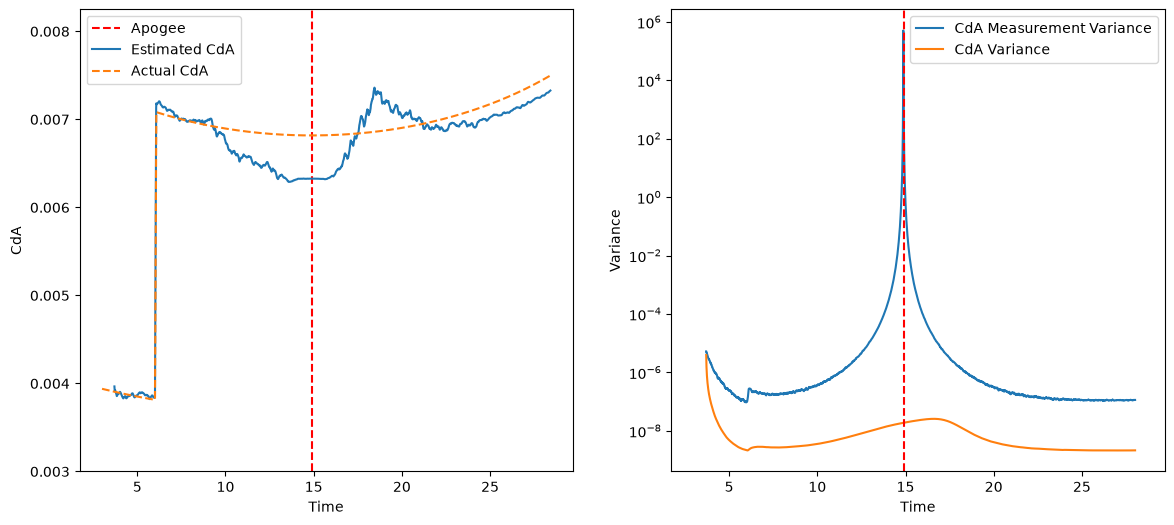

In [ ]:
# plot the CdA estimate over time, with the actual CdA as a dashed line
absTimestamps = np.array([i.timestamp for i in flightData if i.controlSoftwareData is not None ])

print("Start time: ", absTimestamps[0])

CdA_estimate = np.array([i.controlSoftwareData.cdEstimate for i in flightData if i.controlSoftwareData is not None ])
CdA_actual = np.array([CdA(v=i.verticalVelocity, a=i.verticalAcceleration) for i in flightData if i.controlSoftwareData is not None])

# use the cdasaver to also access the raw z values and plot them
cda_raw_values = np.array([i for i in cdaSaver_.z if i is not None]) if cdaSaver_ is not None else []
saverTimeSlots = np.arange(CDA_ESTIMATE_START_T, CDA_ESTIMATE_START_T + len(cda_raw_values)*TIMESTEP, TIMESTEP) if cdaSaver_ is not None else []



# Add a second subplot on the right, that shows the CdA variance using the saver.P
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6),sharex=True)

measurement_variances = [i for i in cdaSaver_.R if i is not None] if cdaSaver_ is not None else []
ax2.plot(saverTimeSlots, measurement_variances, label='CdA Measurement Variance')

process_variances = [i[0,0] for i in cdaSaver_.P if i is not None] if cdaSaver_ is not None else []
ax2.plot(saverTimeSlots, process_variances, label='CdA Variance')
ax2.set_xlabel('Time')
ax2.set_ylabel('Variance')
# make logarithmic
ax2.set_yscale("log")     # Logarithmic y-axis
ax2.legend()

# Add a vertical dashed red line at apogee, so time = 15s
ax1.axvline(x=apogee_time, color='r', linestyle='--', label='Apogee')
ax2.axvline(x=apogee_time, color='r', linestyle='--', label='Apogee')


ax1.plot(absTimestamps, CdA_estimate, label='Estimated CdA')
ax1.plot(absTimestamps, CdA_actual, linestyle='--', label='Actual CdA')
# ax1.plot(saverTimeSlots, cda_raw_values, linestyle=':', label='Raw CdA Measurement')
ax1.set_xlabel('Time')
ax1.set_ylabel('CdA')

# get 90th percentile of the CdA_actual and set the y limit to that
ax1.set_ylim(0.003, max(CdA_actual) * 1.1)  # Add a little margin above the 90th percentile

ax1.legend()
plt.show()

## Explanation for data and estimate
Our measurement variance is linearized using acceleration and velocity, since velocity approaches zero at apogee (vertica red dashed line) the measurement noise is at a singularity (both partial derivatives divide by v to a power). The filter therefore puts almost all of its trust in the predictions and stays quite consistent. 

### Examining slow step response
As a first measure I will include a *B* and *u* term to the filter to tell it that CDA will change quickly and a lot in the following time span.